# Klasterisasi dan Ekonometrika Panel-Spasial Pasar Tenaga Kerja Indonesia
### ACTION 2026 — Annual Competition of Data Science (UNESA)
**Subtema:** *“Turning Insight into Opportunity: Analisis Pengangguran Terbuka untuk Pemerataan Kesempatan Kerja”*  
**Unit Analisis:** 38 Provinsi di Indonesia (dengan panel seimbang 34 provinsi periode 2017–2024 = 272 observasi)  
**Sumber Data:** Badan Pusat Statistik (Sakernas 2017–2024 & Indikator Pasar Tenaga Kerja)

| Peran | Variabel | Makna dalam Pasar Tenaga Kerja | Satuan |
|---|---|---|:---:|
| **Y** | `TPT_Total` | Tingkat Pengangguran Terbuka (indikator utama penyerapan kerja) | % |
| **X1** | `Informal` | Proporsi pekerja sektor informal (penyangga subsisten) | % |
| **X2** | `log(Upah)` | Logaritma rata-rata upah bersih buruh/karyawan | log(Rp) |
| **X3** | `Educated_Mismatch` | Rasio mismatch pengangguran terdidik (SMK & PT vs SD) | rasio |

---


## 0. Setup Lingkungan & Dependensi


In [1]:
import warnings
warnings.filterwarnings('ignore')
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RS = 42
np.random.seed(RS)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight', 'font.size': 9})

HIJAU = '#2F7D6E'
BATA  = '#C0392B'
PASIR = '#D9B26F'
ABU   = '#8896A0'

DATA_DIR = '../data/clean'
CHARTS_DIR = '../assets/charts'
print("Setup selesai. Siap membaca data resmi BPS.")


Setup selesai. Siap membaca data resmi BPS.


## 1. Memuat Data Panel & Georeferensi 38 Provinsi Indonesia


In [2]:
master_38 = pd.read_csv(f'{DATA_DIR}/master_panel_provinsi_2024.csv')
panel_hist = pd.read_csv(f'{DATA_DIR}/panel_tpt_provinsi_2017_2024.csv')
coords = pd.read_csv(f'{DATA_DIR}/koordinat_provinsi_indonesia.csv')
dist_mat = pd.read_csv(f'{DATA_DIR}/jarak_km_provinsi_indonesia.csv', index_col=0)
W_knn4 = pd.read_csv(f'{DATA_DIR}/W_knn4_indonesia.csv', index_col=0)

df_prov = master_38[master_38["Provinsi"] != "Indonesia"].copy()
print(f"Total Provinsi Teranalisis : {len(df_prov)} Provinsi")
print(f"Total Panel Historis      : {len(panel_hist) - 1} Provinsi x 8 Tahun (2017-2024)")
display(coords.head(5))


Total Provinsi Teranalisis : 38 Provinsi
Total Panel Historis      : 34 Provinsi x 8 Tahun (2017-2024)


,Provinsi,lat,lon,pulau,ibukota
0,Aceh,5.5483,95.3238,Sumatera,Banda Aceh
1,Sumatera Utara,3.5952,98.6722,Sumatera,Medan
2,Sumatera Barat,-0.9471,100.4172,Sumatera,Padang
3,Riau,0.5071,101.4478,Sumatera,Pekanbaru
4,Jambi,-1.6101,103.6131,Sumatera,Jambi


## 2. Autokorelasi Spasial Global: Moran's I Lintasan Waktu (2017–2024)
Langkah pertama: menguji apakah pengangguran antar-provinsi di Indonesia bersifat acak atau mengelompok secara geografis.


,tahun,moran_i,expected_i,p_value,status
0,2017,0.1759,-0.0303,0.039,Mengelompok Signifikan
1,2018,0.1788,-0.0303,0.025,Mengelompok Signifikan
2,2019,0.2373,-0.0303,0.011,Mengelompok Signifikan
3,2020,0.2309,-0.0303,0.021,Mengelompok Signifikan
4,2021,0.1462,-0.0303,0.057,Acak / Tidak Signifikan
5,2022,0.2147,-0.0303,0.015,Mengelompok Signifikan
6,2023,0.2661,-0.0303,0.006,Mengelompok Signifikan
7,2024,0.2457,-0.0303,0.011,Mengelompok Signifikan


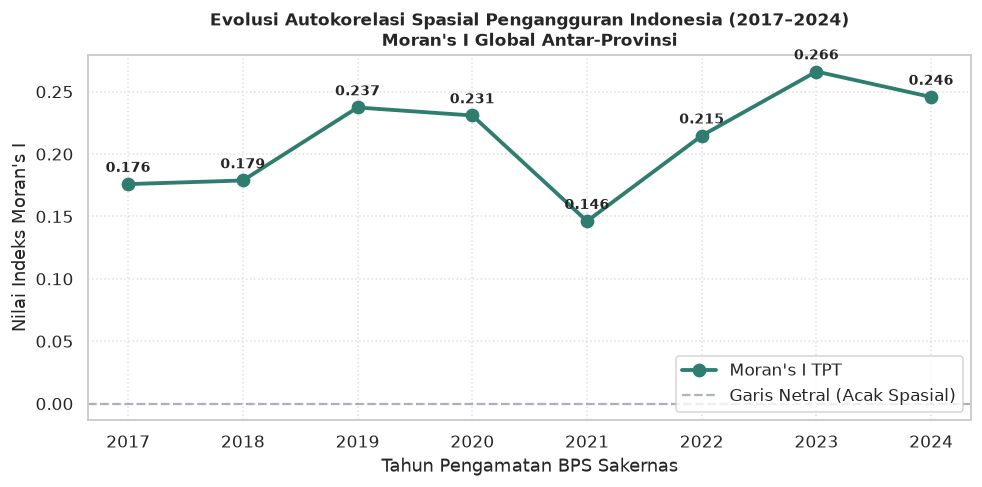

In [3]:
df_moran = pd.read_csv(f'{DATA_DIR}/moran_lintasan_tahun_tpt.csv')
display(df_moran)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df_moran["tahun"], df_moran["moran_i"], marker="o", color=HIJAU, linewidth=2.5, markersize=8, label="Moran's I TPT")
ax.axhline(0, color=ABU, linestyle="--", alpha=0.7, label="Garis Netral (Acak Spasial)")
ax.set_title("Evolusi Autokorelasi Spasial Pengangguran Indonesia (2017–2024)\nMoran's I Global Antar-Provinsi", fontsize=11, fontweight="bold")
ax.set_xlabel("Tahun Pengamatan BPS Sakernas")
ax.set_ylabel("Nilai Indeks Moran's I")
ax.grid(True, linestyle=":", alpha=0.6)
for _, r in df_moran.iterrows():
    ax.annotate(f"{r['moran_i']:.3f}", (r['tahun'], r['moran_i']), textcoords="offset points", xytext=(0, 8), ha='center', fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 3. Autokorelasi Spasial Lokal: LISA 2024 (Local Indicators of Spatial Association)
Mengidentifikasi kantong pengangguran regional (*Hotspot High-High*), wilayah agraris (*Coldspot Low-Low*), dan wilayah *shelter*.


Distribusi Kuadran LISA 2024:


kuadran
Low-Low (Coldspot / Agraris)            16
High-High (Hotspot Pengangguran)        11
Low-High (Shelter di Tengah Hotspot)     6
High-Low (Anomali Mandiri Tinggi)        5
Name: count, dtype: int64

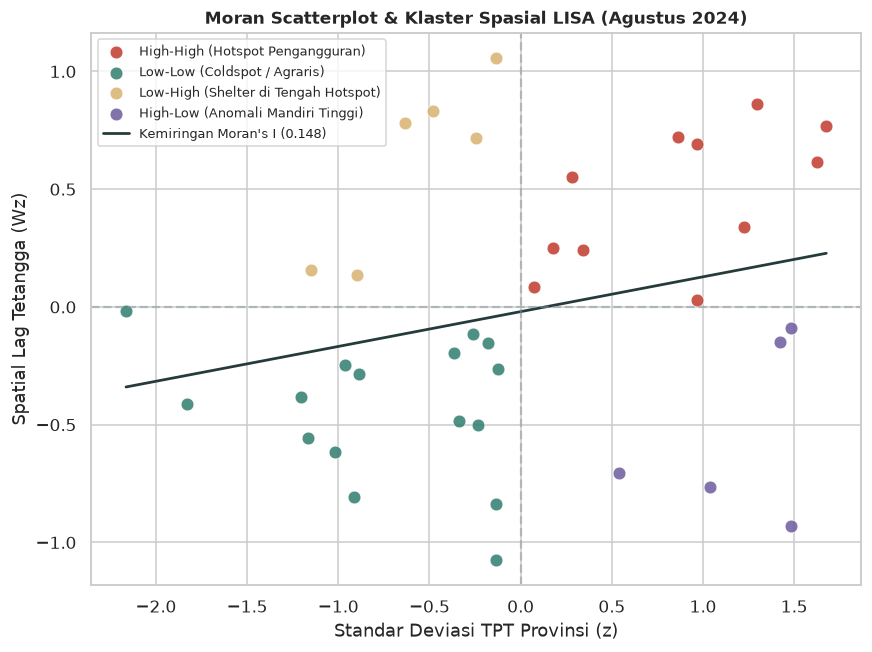

In [4]:
df_lisa = pd.read_csv(f'{DATA_DIR}/lisa_provinsi_2024.csv')
print("Distribusi Kuadran LISA 2024:")
display(df_lisa["kuadran"].value_counts())

fig, ax = plt.subplots(figsize=(8, 6))
colors_lisa = {
    "High-High (Hotspot Pengangguran)": BATA,
    "Low-Low (Coldspot / Agraris)": HIJAU,
    "Low-High (Shelter di Tengah Hotspot)": PASIR,
    "High-Low (Anomali Mandiri Tinggi)": "#6C5B9E"
}
for quad, col in colors_lisa.items():
    sub = df_lisa[df_lisa["kuadran"] == quad]
    ax.scatter(sub["z_TPT"], sub["lag_z_TPT"], color=col, s=70, alpha=0.85, label=quad, edgecolors="white", linewidth=0.5)

m_slope, b_intercept = np.polyfit(df_lisa["z_TPT"], df_lisa["lag_z_TPT"], 1)
x_line = np.linspace(df_lisa["z_TPT"].min(), df_lisa["z_TPT"].max(), 50)
ax.plot(x_line, m_slope * x_line + b_intercept, color='#243B3A', linewidth=1.8, label=f"Kemiringan Moran's I ({m_slope:.3f})")
ax.axvline(0, color=ABU, linestyle="--", alpha=0.5)
ax.axhline(0, color=ABU, linestyle="--", alpha=0.5)
ax.set_title("Moran Scatterplot & Klaster Spasial LISA (Agustus 2024)", fontsize=11, fontweight="bold")
ax.set_xlabel("Standar Deviasi TPT Provinsi (z)")
ax.set_ylabel("Spatial Lag Tetangga (Wz)")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()


## 4. Pemodelan Ekonometrika Spasial: OLS vs SLX vs SAR vs SEM vs SDM
Membandingkan model standar non-spasial (OLS) dengan model yang mengakomodasi efek spasial (SLX, SAR, SEM, SDM).


,Model,Param,LogLik,AIC,rho_lambda,R2,Terpilih
0,OLS (Standar Non-Spasial),4,-57.15,122.31,-,0.391,False
1,SLX (Spatial Lag of X),7,-51.56,117.11,-,0.547,False
2,SAR (Spatial Autoregressive),5,-56.28,122.56,0.24,0.425,False
3,SEM (Spatial Error Model),5,-56.16,122.31,0.33,0.384,False
4,SDM (Spatial Durbin Model),8,-51.55,119.09,0.03,0.547,True


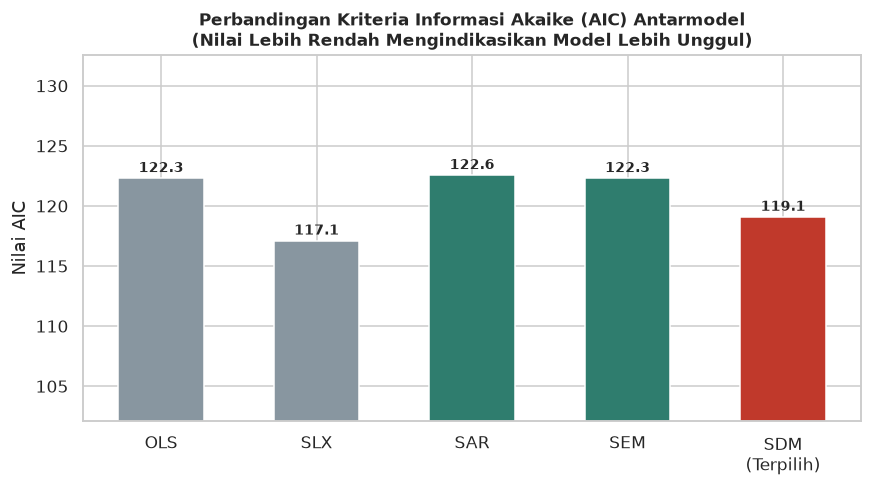

In [5]:
df_models = pd.read_csv(f'{DATA_DIR}/model_spasial_perbandingan.csv')
display(df_models)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(df_models["Model"], df_models["AIC"], color=[ABU, ABU, HIJAU, HIJAU, BATA], width=0.55)
ax.set_title("Perbandingan Kriteria Informasi Akaike (AIC) Antarmodel\n(Nilai Lebih Rendah Mengindikasikan Model Lebih Unggul)", fontsize=11, fontweight="bold")
ax.set_ylabel("Nilai AIC")
ax.set_xticklabels(["OLS", "SLX", "SAR", "SEM", "SDM\n(Terpilih)"])
ax.set_ylim(df_models["AIC"].min() - 15, df_models["AIC"].max() + 10)
for b in bars:
    h = b.get_height()
    ax.annotate(f"{h:.1f}", (b.get_x() + b.get_width() / 2, h), textcoords="offset points", xytext=(0, 4), ha='center', fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Dekomposisi Efek Spasial LeSage–Pace (SDM)
Menghitung efek langsung (*Direct Effect*), efek limpahan (*Spillover Effect*), dan efek total dari informalitas, upah, dan mismatch pendidikan.


,Variabel,Koef_Domestik (Beta),Koef_Spasial (Theta),Efek_Langsung (Direct),Efek_Limpahan (Spillover / Indirect),Efek_Total
0,Informalitas (%),-0.0813,-0.0366,-0.0815,-0.0400,-0.1215
1,log(Upah),0.3549,4.3112,0.3791,4.4313,4.8104
2,Rasio Mismatch Terdidik,0.0499,0.8781,0.0549,0.9019,0.9568


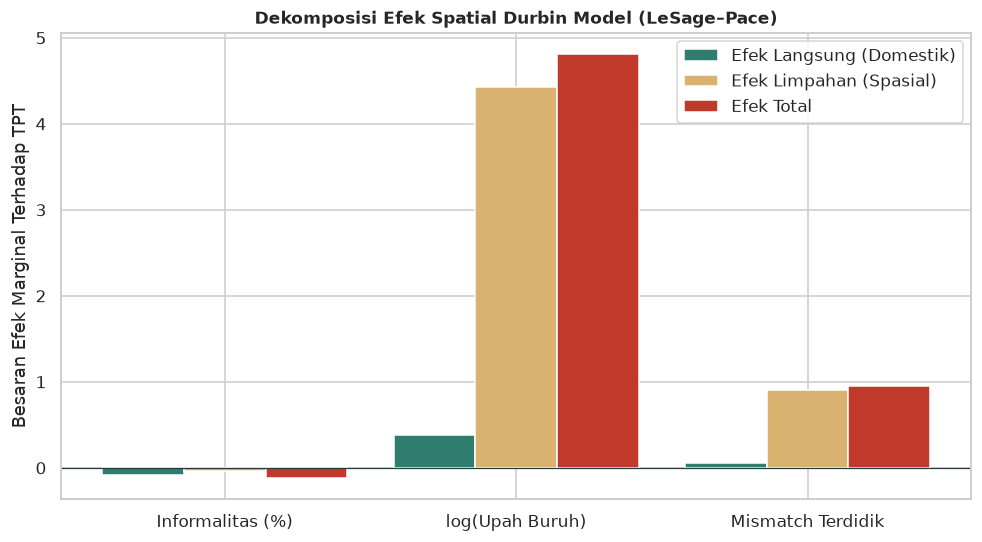

In [6]:
df_lesage = pd.read_csv(f'{DATA_DIR}/dekomposisi_efek_sdm_tpt.csv')
display(df_lesage)

x_indices = np.arange(len(df_lesage))
width = 0.28
fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x_indices - width, df_lesage["Efek_Langsung (Direct)"], width, label="Efek Langsung (Domestik)", color=HIJAU)
rects2 = ax.bar(x_indices, df_lesage["Efek_Limpahan (Spillover / Indirect)"], width, label="Efek Limpahan (Spasial)", color=PASIR)
rects3 = ax.bar(x_indices + width, df_lesage["Efek_Total"], width, label="Efek Total", color=BATA)
ax.set_title("Dekomposisi Efek Spatial Durbin Model (LeSage–Pace)", fontsize=11, fontweight="bold")
ax.set_xticks(x_indices)
ax.set_xticklabels(["Informalitas (%)", "log(Upah Buruh)", "Mismatch Terdidik"])
ax.axhline(0, color='#243B3A', linestyle="-", linewidth=0.8)
ax.set_ylabel("Besaran Efek Marginal Terhadap TPT")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 6. Grid Search Klaster Multidimensi & Uji Stabilitas Subsampling Bootstrap


In [7]:
df_grid = pd.read_csv(f'{DATA_DIR}/grid_konfigurasi_klaster.csv')
df_fitur = pd.read_csv(f'{DATA_DIR}/fitur_lintasan_provinsi.csv')
print(f"Total Konfigurasi Teruji : {len(df_grid)}")
print(f"Konfigurasi Lolos Syarat : {len(df_grid[df_grid['Layak']])}")
display(df_grid[df_grid["Layak"]].sort_values("Silhouette", ascending=False).head(5))


Total Konfigurasi Teruji : 216
Konfigurasi Lolos Syarat : 72


,Ruang,Praproses,Proyeksi,Algoritma,k,Pangsa_Terbesar,Min_Anggota,Layak,Silhouette
204,SERI,MinMax,PCA2,KMeans,2,0.588,14,True,0.5467
208,SERI,MinMax,PCA2,Ward,3,0.382,9,True,0.5332
156,SERI,Standard,PCA2,KMeans,2,0.588,14,True,0.5108
157,SERI,Standard,PCA2,Ward,2,0.676,11,True,0.4994
180,SERI,Robust,PCA2,KMeans,2,0.588,14,True,0.4992
